# Rythu Mitra — NLP testing and evidence
**Presentation companion | SR University**

Open this notebook in VS Code/Jupyter with the project's Python environment, then use **Run All**. It works from the project root or `notebooks` folder. Saved outputs are included for presentation.

This notebook checks existing artifacts without retraining. It never loads `.env`, prints credentials, or calls paid/live services. Weather and mandi browser checks use explicitly simulated responses: they prove application behaviour, not current weather or prices.

## Evidence checklist
1. Dataset, labels, split integrity and leakage checks.
2. Unicode preprocessing and saved TF-IDF features.
3. Nine model/feature experiments: primary 319-question benchmark and secondary workbook results.
4. Selected-model accuracy, precision, recall, F1, confusion matrices and errors.
5. Original 150-question challenge, 319-question challenge, cross-script evaluation and routing rules.
6. Telugu, English and mixed questions; crops, locations and topics.
7. API validation, missing/failed price services, practical guidance and mobile/language browser tests.

**Interpretation:** authored challenges are project-written, not independent farmer surveys. Intent correctness does not establish agricultural diagnosis or advice correctness. The optional IndicBERT experiment is NOT RUN.


In [1]:
from pathlib import Path
import sys, json, subprocess, os, hashlib, platform
from datetime import datetime, timezone
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'ml/models/metrics.json').exists()), None)
assert ROOT is not None, 'Open the notebook from NLP_PROJECT or its notebooks folder.'
sys.path[:0] = [str(ROOT), str(ROOT/'.vendor')]
import dotenv
dotenv.load_dotenv = lambda *args, **kwargs: False  # Notebook process only: do not open .env.
import pandas as pd
import numpy as np
import joblib
from IPython.display import display, Image
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from ml.preprocess import normalize, script_type
from ml.slots import route_intent, extract_slots
pd.set_option('display.max_colwidth', 110)
def read_json(name): return json.loads((ROOT/name).read_text(encoding='utf-8'))
def show(frame): display(frame)
def scores(y, pred):
    return {'accuracy': accuracy_score(y,pred), 'macro_F1': f1_score(y,pred,average='macro',zero_division=0)}
metrics = read_json('ml/models/metrics.json')
robust = read_json('reports/robustness_metrics.json')
model = joblib.load(ROOT/'ml/models/best_model.joblib')
print('Execution UTC:', datetime.now(timezone.utc).isoformat())
print('Python:', platform.python_version(), '| Selected:', metrics['selected']['model'], '/', metrics['selected']['features'])
manifest=[]
for name in ['ml/models/best_model.joblib','ml/models/metrics.json','reports/robustness_metrics.json','data/handwritten_test_v2.csv']:
    manifest.append({'artifact':name,'SHA256':hashlib.sha256((ROOT/name).read_bytes()).hexdigest()})
show(pd.DataFrame(manifest))


Execution UTC: 2026-11-12T18:38:03.296329+00:00
Python: 3.13.1 | Selected: Logistic Regression / word


,artifact,SHA256
0,ml/models/best_model.joblib,835e1b44d800ba6e3b79304e447d738b04495b0939f1ffd16ed4db73f30bab13
1,ml/models/metrics.json,8c8d0465384841b011862511a021ffd28879cdc325d0712cf47e2415608c78f0
2,reports/robustness_metrics.json,e775d4f6aafc1e9fec340695f4ef8bb33d1393a38b6113d001d06d50c95884c1
3,data/handwritten_test_v2.csv,8b601f7cc2ac5a27609582aa44aacc56faf927d97435da2a4a2be1ff675a876e


## 1. Data and split evidence
Display actual split sizes, source provenance and intent coverage. Assert that exact normalized questions and group IDs do not cross splits, that held-out workbook sets contain no synthetic examples, and that authored challenges do not appear in training. The full pytest run below additionally checks cosine near-duplicates at the project's 0.92 threshold.


In [2]:
train = pd.read_csv(ROOT/'data/train.csv')
validation = pd.read_csv(ROOT/'data/validation_original.csv')
test = pd.read_csv(ROOT/'data/test_original.csv')
old = pd.read_csv(ROOT/'data/handwritten_test.csv')
hand = pd.read_csv(ROOT/'data/handwritten_test_v2.csv')
frames = {'train':train,'validation':validation,'workbook test':test}
show(pd.DataFrame([{'split':k,'rows':len(v),'intents':v.intent.nunique(),'sources':', '.join(sorted(v.source.unique()))} for k,v in frames.items()]))
show(pd.crosstab(train.intent, train.source))
for name, frame in frames.items():
    assert frame['query'].notna().all() and frame.normalized.ne('').all(), name
    assert not frame.normalized.duplicated().any(), name
for a,b in [('train','validation'),('train','workbook test'),('validation','workbook test')]:
    assert not set(frames[a].normalized) & set(frames[b].normalized)
    assert not set(frames[a].group) & set(frames[b].group)
assert set(validation.source) == set(test.source) == {'workbook'}
for challenge in [old, hand]:
    assert challenge['query'].is_unique
    assert not set(challenge['query'].map(normalize)) & set(train.normalized)
assert not set(old['query'].map(normalize)) & set(hand['query'].map(normalize))
assert len(hand) == robust['rows'] == 319
print('PASS: exact/group leakage and benchmark overlap checks.')


PASS: exact/group leakage and benchmark overlap checks.


,split,rows,intents,sources
0,train,36443,8,"synthetic, workbook"
1,validation,4101,7,workbook
2,workbook test,3850,7,workbook


source,synthetic,workbook
intent,,
crop_disease,2369,2193
fertilizer,2334,2149
govt_scheme,2036,984
irrigation,2082,1034
market_price,2060,984
other_agri,3117,11779
out_of_scope,161,0
weather,2047,1114


## 2. Preprocessing and feature evidence
Unicode Telugu marks are retained; punctuation, URLs and digits are removed for intent features. Entity and quantity extraction are separate. These examples are demonstrations, not an accuracy benchmark.


In [3]:
examples = ['వరి పంటలో తెగుళ్ల నివారణకు ఏ మందు వాడాలి?', 'naaku varri ki purugulu unnayi!!!', 'Warangal market lo mirchi ధర ఎంత?', 'UREA 2 acres https://example.invalid']
show(pd.DataFrame([{'input':q,'normalized':normalize(q),'script':script_type(q)} for q in examples]))
print('Saved pipeline steps:', list(model.named_steps))
features = model.named_steps['features']
x = features.transform([examples[1]])
print('Saved feature transform:', x.shape, '| nonzero features:', x.nnz)
assert normalize(normalize(examples[0])) == normalize(examples[0])
assert 'వరి' in normalize(examples[0])
print('PASS: Telugu preservation and normalization idempotence.')


Saved pipeline steps: ['features', 'model']
Saved feature transform: (1, 20000) | nonzero features: 7
PASS: Telugu preservation and normalization idempotence.


,input,normalized,script
0,వరి పంటలో తెగుళ్ల నివారణకు ఏ మందు వాడాలి?,వరి పంటలో తెగుళ్ల నివారణకు ఏ మందు వాడాలి,telugu
1,naaku varri ki purugulu unnayi!!!,naaku vari ki purugu unnayi,romanized
2,Warangal market lo mirchi ధర ఎంత?,warangal market lo mirchi ధర ఎంత,mixed
3,UREA 2 acres https://example.invalid,urea acres,english


## 3. Nine experiments — fresh primary predictions + recorded workbook diagnostics
All nine saved models predict the same 319 authored questions here. Scores must match the stored report. Workbook scores and CV/validation values are recorded training-run evidence; the selected workbook model is rechecked in the next section. Selection used validation scores, not this challenge. No models are fitted in this notebook.


In [4]:
comparison = pd.DataFrame(metrics['comparison'])
assert len(comparison) == 9
rows=[]
for experiment in metrics['comparison']:
    estimator = joblib.load(ROOT/'ml/models/experiments'/f"{experiment['key']}.joblib")
    p = estimator.predict(hand['query'])
    result = scores(hand.intent,p)
    saved = next(r for r in robust['raw_models'] if r['experiment']==experiment['key'])
    assert abs(result['accuracy']-saved['accuracy']) < 1e-10
    assert abs(result['macro_F1']-saved['macro_f1']) < 1e-10
    rows.append({'model':experiment['model'],'features':experiment['features'],
                 '319 accuracy (fresh)':result['accuracy'],'319 macro-F1 (fresh)':result['macro_F1'],
                 'workbook accuracy (saved)':experiment['test_accuracy'],'workbook macro-F1 (saved)':experiment['test_macro_f1'],
                 'validation macro-F1 (saved)':experiment['validation_macro_f1']})
show(pd.DataFrame(rows).round(6))
print('PASS: all nine authored-benchmark scores reproduce saved metrics.')


PASS: all nine authored-benchmark scores reproduce saved metrics.


,model,features,319 accuracy (fresh),319 macro-F1 (fresh),workbook accuracy (saved),workbook macro-F1 (saved),validation macro-F1 (saved)
0,Naive Bayes,word,0.727273,0.718978,0.989091,0.981915,0.975934
1,Logistic Regression,word,0.789969,0.800238,1.000000,1.000000,1.000000
2,Linear SVM,word,0.827586,0.826930,1.000000,1.000000,1.000000
3,Naive Bayes,char,0.833856,0.825963,0.974286,0.960688,0.958637
4,Logistic Regression,char,0.880878,0.883349,1.000000,1.000000,1.000000
5,Linear SVM,char,0.862069,0.857770,1.000000,1.000000,1.000000
6,Naive Bayes,combined,0.836991,0.829802,0.988571,0.981784,0.973599
7,Logistic Regression,combined,0.880878,0.884850,1.000000,1.000000,1.000000
8,Linear SVM,combined,0.874608,0.871127,1.000000,1.000000,1.000000


## 4. Selected model — fresh generalization checks
The workbook is templated; the 150 and 319 authored sets have different wording, class distributions and sizes. They are not directly equivalent difficulty tests. Cross-script results use a **different combined-feature Logistic Regression model**; only its saved row predictions are re-scored here, without retraining.


In [5]:
selected_predictions={}
evaluation=[]
for name, frame, recorded in [('Workbook (secondary)',test, {'accuracy':metrics['selected']['test_accuracy'],'macro_f1':metrics['selected']['test_macro_f1']}), ('Authored original',old,metrics['handwritten']), ('Authored larger (primary)',hand,robust['selected_raw'])]:
    p=model.predict(frame['query']); selected_predictions[name]=p
    result=scores(frame.intent,p)
    assert abs(result['accuracy']-recorded['accuracy']) < 1e-10
    assert abs(result['macro_F1']-recorded['macro_f1']) < 1e-10
    evaluation.append({'evaluation':name,'rows':len(frame),'evidence':'fresh saved-model inference',**result})
transfer=pd.read_csv(ROOT/'reports/cross_script_predictions.csv')
result=scores(transfer.intent,transfer.prediction)
assert abs(result['accuracy']-robust['cross_script']['accuracy']) < 1e-10
assert abs(result['macro_F1']-robust['cross_script']['macro_f1']) < 1e-10
workbook=pd.read_csv(ROOT/'data/workbook_clean.csv')
transfer_train=workbook[workbook.split.eq('train') & workbook.version.isin(['query_english','query_code_mixed'])]
assert not set(transfer_train.group) & set(transfer.group)
assert set(transfer.version)=={'query_telugu'}
evaluation.append({'evaluation':'Cross-script (separate LR combined)','rows':len(transfer),'evidence':'re-scored saved predictions',**result})
show(pd.DataFrame(evaluation).round(6))
print('PASS: selected-model metrics and cross-script recorded scores; transfer groups disjoint.')


PASS: selected-model metrics and cross-script recorded scores; transfer groups disjoint.


,evaluation,rows,evidence,accuracy,macro_F1
0,Workbook (secondary),3850,fresh saved-model inference,1.000000,1.000000
1,Authored original,150,fresh saved-model inference,0.873333,0.868187
2,Authored larger (primary),319,fresh saved-model inference,0.789969,0.800238
3,Cross-script (separate LR combined),1256,re-scored saved predictions,0.546975,0.116393


## 5. Confusion matrices, class scores and visible mistakes
Rows are true labels and columns are predicted labels. Show both the secondary workbook and primary authored challenge. Inspect errors instead of presenting only successful examples.


Primary benchmark wrong predictions: 67 / 319


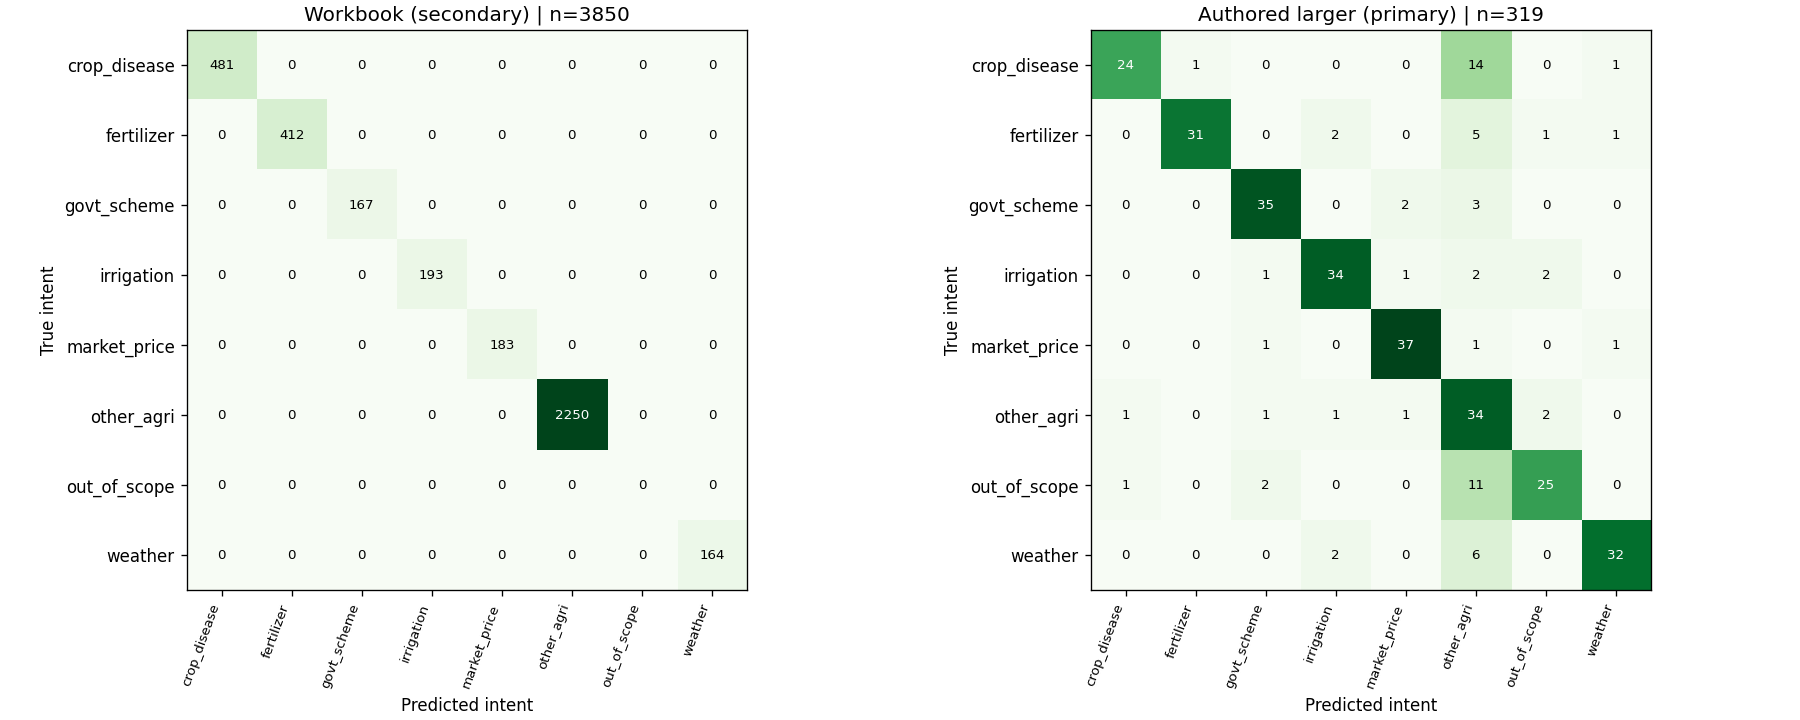

,precision,recall,f1-score,support
crop_disease,0.923077,0.600000,0.727273,40.000000
fertilizer,0.968750,0.775000,0.861111,40.000000
govt_scheme,0.875000,0.875000,0.875000,40.000000
irrigation,0.871795,0.850000,0.860759,40.000000
market_price,0.902439,0.925000,0.913580,40.000000
other_agri,0.447368,0.850000,0.586207,40.000000
out_of_scope,0.833333,0.641026,0.724638,39.000000
weather,0.914286,0.800000,0.853333,40.000000
accuracy,0.789969,0.789969,0.789969,0.789969
macro avg,0.842006,0.789503,0.800238,319.000000


,query,intent,prediction
2,vari panta aakulu yellow gaa marayi,crop_disease,other_agri
4,mamidi aakulu endipotundi doctor evaru,crop_disease,other_agri
5,vankaya kayallo purugul paddayi,crop_disease,other_agri
8,arati veru kullipothundi,crop_disease,other_agri
9,dosakaya lo randhralu kanipistunnayi,crop_disease,other_agri
11,cotton yellowing,crop_disease,fertilizer
15,there are tiny caterpillars inside my brinjal fruits,crop_disease,other_agri
20,వరికి పసుపు రంగు వచ్చింది ఏమి చేయాలి,crop_disease,other_agri
23,టమాటా ఆకుల మచ్చల గురించి సలహా కావాలి,crop_disease,other_agri
24,దానిమ్మ వేర్లు కుళ్ళుతున్నాయి,crop_disease,other_agri


In [6]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import io
labels=list(model.classes_)
fig,axes=plt.subplots(1,2,figsize=(15,6),layout='constrained')
for ax,name,frame in [(axes[0],'Workbook (secondary)',test),(axes[1],'Authored larger (primary)',hand)]:
    cm=confusion_matrix(frame.intent,selected_predictions[name],labels=labels)
    ax.imshow(cm,cmap='Greens')
    ax.set(xticks=range(len(labels)),yticks=range(len(labels)),xticklabels=labels,yticklabels=labels,xlabel='Predicted intent',ylabel='True intent',title=f'{name} | n={len(frame)}')
    plt.setp(ax.get_xticklabels(),rotation=70,ha='right',fontsize=8)
    for (i,j),value in np.ndenumerate(cm): ax.text(j,i,str(value),ha='center',va='center',fontsize=8,color='white' if value>cm.max()/2 else 'black')
buf=io.BytesIO(); fig.savefig(buf,format='png',dpi=120); plt.close(fig); display(Image(data=buf.getvalue()))
primary_predictions=selected_predictions['Authored larger (primary)']
show(pd.DataFrame(classification_report(hand.intent,primary_predictions,output_dict=True,zero_division=0)).T.round(6))
errors=hand.assign(prediction=primary_predictions)
errors=errors[errors.intent.ne(errors.prediction)]
print('Primary benchmark wrong predictions:',len(errors),'/',len(hand))
show(errors[['query','intent','prediction']].head(12))


## 6. Raw ML versus routing rules — keep evidence separate
The stored deployed-rule result belongs to the recorded evaluation run. Guidance/routing has since been updated. Recompute the **current** rules below and display both results; a difference is reported, not silently substituted into the old report. Clarification does not mean a complete answer was delivered.


In [7]:
saved_primary=pd.read_csv(ROOT/'reports/handwritten_v2_predictions.csv')
saved_result=scores(saved_primary.intent,saved_primary.deployed_prediction)
assert abs(saved_result['accuracy']-robust['deployed_rules']['accuracy']) < 1e-10
assert abs(saved_result['macro_F1']-robust['deployed_rules']['macro_f1']) < 1e-10
probabilities=model.predict_proba(hand['query'])
routed=[]
for q,p,raw in zip(hand['query'],probabilities,primary_predictions):
    top=sorted(p,reverse=True)
    routed.append(route_intent(q,str(raw),float(top[0]),float(top[0]-top[1])))
current=scores(hand.intent,[r['intent'] for r in routed])
show(pd.DataFrame([
    {'mode':'Raw selected model (fresh)',**scores(hand.intent,primary_predictions)},
    {'mode':'Routing rules (recorded run)',**saved_result},
    {'mode':'Routing rules (current code, fresh)',**current}
]).round(6))
print('Recorded clarification fraction:',robust['clarification_rate'])
print('Current clarification fraction:',np.mean([r['clarify'] for r in routed]))
print('Rule outputs can change after routing fixes; recorded experiment numbers are untouched.')


Recorded clarification fraction: 0.3824451410658307
Current clarification fraction: 0.3730407523510972
Rule outputs can change after routing fixes; recorded experiment numbers are untouched.


,mode,accuracy,macro_F1
0,Raw selected model (fresh),0.789969,0.800238
1,Routing rules (recorded run),0.833856,0.838835
2,"Routing rules (current code, fresh)",0.846395,0.851416


## 7. User questions — Telugu, English and mixed (30 cases)
Execute the real Flask prediction route with the saved model. Validate topic, crop and location against expected cases. Raw ML and routed predictions remain separate columns. This checks recognition, not the clinical/agronomic correctness of an answer; the browser suite verifies rendered guidance.


In [8]:
from app import create_app
client=create_app().test_client()
cases=read_json('tests/question_cases.json')
question_rows=[]
for case in cases:
    response=client.post('/predict',json={'query':case['q']})
    assert response.status_code==200
    answer=response.get_json()
    assert answer['intent']==case['intent'],case['q']
    for field in ['crop','location','question_topic']:
        if field in case: assert answer[field]==case[field], (case['q'],field)
    question_rows.append({'question':case['q'],'expected':case['intent'],'raw ML':answer.get('raw_intent'),'routed':answer['intent'],'crop':answer.get('crop'),'location':answer.get('location'),'pass':True})
show(pd.DataFrame(question_rows))
potato=client.post('/predict',json={'query':'na potato chetu ki holes unnay em cheyali'}).get_json()
show(pd.DataFrame([{k:potato.get(k) for k in ['intent','raw_intent','crop','symptoms','clarify']}]))
assert potato['crop']=='potato' and potato['intent']=='crop_disease' and 'holes' in potato['symptoms']
print('PASS:',len(cases),'language/topic cases and original potato question.')


PASS: 30 language/topic cases and original potato question.


,question,expected,raw ML,routed,crop,location,pass
0,వరి పంటలో తెగుళ్ల నివారణకు ఏ మందు వాడాలి?,crop_disease,crop_disease,crop_disease,paddy,None,True
1,Which pesticide should be used to control pests in paddy crops?,crop_disease,fertilizer,crop_disease,paddy,None,True
2,na vari panta ki pests unnay ఏ మందు వాడాలి?,crop_disease,crop_disease,crop_disease,paddy,None,True
3,రేపు మా ప్రాంతంలో వర్షం పడే అవకాశం ఉందా?,weather,weather,weather,None,None,True
4,Will it rain in our area tomorrow?,weather,weather,weather,None,None,True
5,repu maa area lo rain పడుతుందా?,weather,weather,weather,None,None,True
6,ఈరోజు వరంగల్ మార్కెట్‌లో మిర్చి ధర ఎంత ఉంది?,market_price,market_price,market_price,chilli,Warangal,True
7,What is the price of chili in the Warangal market today?,market_price,market_price,market_price,chilli,Warangal,True
8,వరంగల్ market lo mirchi price entha today?,market_price,market_price,market_price,chilli,Warangal,True
9,రైతు భరోసా పథకానికి ఎలా దరఖాస్తు చేసుకోవాలి?,govt_scheme,govt_scheme,govt_scheme,None,None,True


,intent,raw_intent,crop,symptoms,clarify
0,crop_disease,crop_disease,potato,[holes],False


## 8. Within-intent problem classifier (recorded evidence)
These predictions are conditioned on the known/assigned intent; they are not end-to-end diagnostic accuracy. Re-score saved row predictions and show the saved per-intent metrics. A symptom label is not a confirmed crop diagnosis.


In [9]:
problem=read_json('reports/problem_metrics.json')
problem_rows=pd.read_csv(ROOT/'reports/problem_predictions.csv')
for split,g in problem_rows.groupby('split'):
    assert abs(g.correct.mean()-problem['summary'][split]['accuracy']) < 1e-10
show(pd.DataFrame(problem['summary']).T.round(6))
show(pd.DataFrame(problem['models'])[['intent','classes','train_rows','test_accuracy','test_macro_f1','handwritten_accuracy']].round(6))
print('PASS: recorded problem predictions agree with aggregate accuracy.')


PASS: recorded problem predictions agree with aggregate accuracy.


,rows,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
handwritten,49.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
test,3850.0,0.976883,0.967979,0.987113,0.976786,0.959694,0.976883,0.967826
validation,4101.0,0.966837,0.958045,0.983581,0.969716,0.944133,0.966837,0.954633


,intent,classes,train_rows,test_accuracy,test_macro_f1,handwritten_accuracy
0,crop_disease,22,2773,0.968815,0.930597,1.0
1,fertilizer,13,2707,0.983010,0.917902,1.0
2,govt_scheme,5,1225,0.970060,0.788822,1.0
3,irrigation,7,1318,0.968912,0.840100,1.0
4,market_price,5,1269,0.956284,0.783050,1.0
5,other_agri,51,14896,0.978667,0.969409,1.0
6,weather,7,1403,1.000000,1.000000,1.0


## 9. Run the complete Python test suite
Fresh subprocess execution, with `.env` loading disabled before importing the app. Tests cover preprocessing, crops/entities, split/near-duplicate leakage, model regression, slots, multilingual queries, API bad/empty input, private-file protection, price filters/caching and missing/authentication/timeout/invalid-response cases. Price calls use test fixtures, not a real API key. Failed test processes stop the notebook.


In [10]:
pytest_code = "import dotenv; dotenv.load_dotenv=lambda *a,**k:False; import pytest; raise SystemExit(pytest.main(['-q']))"
python_result=subprocess.run([sys.executable,'-c',pytest_code],cwd=ROOT,capture_output=True,text=True,encoding='utf-8',errors='replace',timeout=600)
print(python_result.stdout)
if python_result.returncode: print(python_result.stderr)
assert python_result.returncode==0, 'Python tests failed; inspect the output.'
python_summary=read_json('reports/test_summary.json')
show(pd.DataFrame([python_summary]))
assert python_summary['failed']==python_summary['errors']==0


........................................................................ [ 11%]
........................................................................ [ 23%]
........................................................................ [ 35%]
........................................................................ [ 46%]
........................................................................ [ 58%]
........................................................................ [ 70%]
........................................................................ [ 82%]
........................................................................ [ 93%]
.....................................                                    [100%]
613 passed in 16.08s



,passed,failed,errors,skipped,exit_status
0,613,0,0,0,0


## 10. Fresh Playwright browser checks
Run three existing suites: requested multilingual questions, practical guidance, and remaining model/weather charts plus Market Prices functionality after removal of its graphs. They include mobile, Telugu/English, empty/failed/single-record service responses and zero/negative-profit calculations. Real saved model inference is used; external weather and price replies are **explicit fixtures**. These tests do not demonstrate live-provider availability. No server needs to be running. Existing Node/Playwright and Chrome/Chromium are required; this notebook installs nothing.


In [11]:
browser_suites=[('questions.cjs','questions_test_results.json'),('practical.cjs','practical_test_results.json'),('charts.cjs','charts_test_results.json')]
browser_summaries=[]
for script,report in browser_suites:
    result=subprocess.run(['node',str(ROOT/'tests'/script)],cwd=ROOT,capture_output=True,text=True,encoding='utf-8',errors='replace',timeout=300)
    print(script, result.stdout.strip())
    if result.returncode: print(result.stderr)
    assert result.returncode==0, f'{script} failed or its runtime is unavailable.'
    details=read_json('reports/'+report)
    assert details['failed']==0 and not details.get('javascript_errors',[])
    browser_summaries.append({'suite':script,'passed':details['passed'],'failed':details['failed'],'JavaScript errors':len(details.get('javascript_errors',[]))})
show(pd.DataFrame(browser_summaries))
print('PASS: browser suites completed with no JavaScript errors.')


questions.cjs {"passed":43,"failed":0,"javascript_errors":[]}
practical.cjs {"passed":28,"failed":0,"javascript_errors":[]}
charts.cjs {"passed":21,"failed":0,"javascript_errors":[]}
PASS: browser suites completed with no JavaScript errors.


,suite,passed,failed,JavaScript errors
0,questions.cjs,43,0,0
1,practical.cjs,28,0,0
2,charts.cjs,21,0,0


## 11. Presentation summary and evidence boundaries
Use the primary authored benchmark for the headline NLP result; show the workbook score as a secondary diagnostic. Present rule-assisted routing separately. Cross-script transfer is a separate model evaluation and reveals a generalization limit. Test counts demonstrate regression coverage, not field accuracy. Live weather/mandi values still depend on provider connectivity and reporting dates. Optional IndicBERT has no claimed result.


In [12]:
summary=[{'evidence':'Fresh Python regression tests','passed':python_summary['passed'],'failed':python_summary['failed']+python_summary['errors']},*browser_summaries]
show(pd.DataFrame(summary).fillna(''))
print('Primary selected raw ML:',scores(hand.intent,primary_predictions))
print('Cross-script saved-prediction evaluation:',scores(transfer.intent,transfer.prediction))
print('IndicBERT:',robust['indicbert']['status'])
print('Completed UTC:',datetime.now(timezone.utc).isoformat())
print('All assertions in this executed notebook passed. No retraining was performed.')


Primary selected raw ML: {'accuracy': 0.7899686520376176, 'macro_F1': 0.8002376862515979}
Cross-script saved-prediction evaluation: {'accuracy': 0.5469745222929936, 'macro_F1': 0.11639250294712479}
IndicBERT: NOT RUN
Completed UTC: 2026-11-12T18:40:10.247089+00:00
All assertions in this executed notebook passed. No retraining was performed.


,evidence,passed,failed,suite,JavaScript errors
0,Fresh Python regression tests,613,0,,
1,,43,0,questions.cjs,0.0
2,,28,0,practical.cjs,0.0
3,,21,0,charts.cjs,0.0
